# Imports

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Code

## Loading images

In [2]:
img1_path= "assets/pano_image1.jpg"
img2_path= "assets/pano_image2.jpg"

In [3]:
img1= cv2.imread(img1_path)
img2= cv2.imread(img2_path)

In [4]:
cv2.imshow('img1', img1)
cv2.imshow('img2', img2)
cv2.waitKey()
cv2.destroyAllWindows()

## Finding matches

In [5]:
def find_correspondences(img1, img2, n_matches):
    # Initialize SIFT detector
    sift = cv2.SIFT_create()

    if len(img1.shape) > 2:
        gray1= cv2.cvtColor(img1,cv2.COLOR_BGR2GRAY)
    else:
        gray1=img1

    if len(img2.shape) > 2:
        gray2= cv2.cvtColor(img2,cv2.COLOR_BGR2GRAY)
    else:
        gray2=img2

    
    # Detect and compute keypoints and descriptors
    kp1, des1 = sift.detectAndCompute(gray1, None)
    kp2, des2 = sift.detectAndCompute(gray2, None)

    # Use BFMatcher with KNN
    bf = cv2.BFMatcher()
    matches = bf.knnMatch(des1, des2, k=2)
    
    # Apply ratio test
    good_matches = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good_matches.append([m])
    
    # Select best n matches
    n= n_matches
    good_matches = [m[0] for m in good_matches]
    good_matches = sorted(good_matches, key=lambda x: x.distance)[:n]
    good_matches = [[m] for m in good_matches]
    
    # Draw matches
    match_img = cv2.drawMatchesKnn(img1, kp1, img2, kp2, good_matches, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    return kp1, kp2, good_matches, match_img

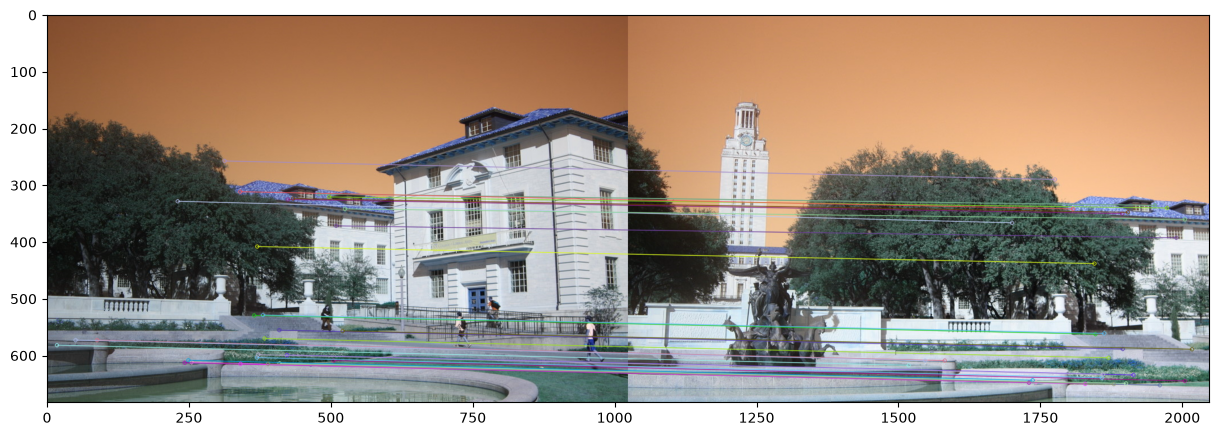

(<matplotlib.image.AxesImage at 0x118ea3ef0>, None)

In [6]:
kp1,kp2,matches, match_img= find_correspondences(img1,img2,30)
plt.figure(figsize=(15, 10))
plt.imshow(match_img), plt.show()

## Computing Homography matrix

In [7]:
def calc_homography(src_pts, dst_pts):
    # Build the system of equations (Ax=b)
    A = []
    for (x, y), (x_prime, y_prime) in zip(src_pts, dst_pts):
        A.append([-x, -y, -1, 0, 0, 0, x * x_prime, y * x_prime, x_prime])
        A.append([0, 0, 0, -x, -y, -1, x * y_prime, y * y_prime, y_prime])
    A = np.array(A)

    # Solve using (SVD)
    _, _, V = np.linalg.svd(A)
    H_normalized = V[-1].reshape(3, 3)

    H_normalized /=  H_normalized[2,2] #Normalize using H(3,3) so that element 3,3 in homography matrix is 1
    
    return H_normalized


In [8]:
def compute_homography(kp1, kp2, matches):
    # Extract matched points and transform them to (2,1) shape
    src_pts = np.float32([kp1[m.queryIdx].pt for m in matches]).reshape(-1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in matches]).reshape(-1, 2)
    
    # Compute homography
    H_norm = calc_homography(src_pts, dst_pts)
    return H_norm

In [9]:
def compute_homography_builtin(kp1, kp2, matches):
    # Extract matched points and transform them to (2,1) shape
    src_pts = np.float32([kp1[m.queryIdx].pt for m in matches]).reshape(-1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in matches]).reshape(-1, 2)
    
    # Compute homography
    H, _ = cv2.findHomography(src_pts, dst_pts)
    return H

In [10]:
H_mat= compute_homography(kp1, kp2, [m[0] for m in matches])
print(H_mat)

[[ 7.53728752e-01  3.24745145e-02  4.49125516e+02]
 [-1.37383161e-01  9.03999876e-01  7.76759737e+01]
 [-2.16997322e-04 -3.90109552e-05  1.00000000e+00]]


## Warping and creating mosiac

In [11]:
def forward_warp(img, H, output_shape):
    h, w = output_shape[:2]
    warped = np.zeros((h, w, 3), dtype=np.uint8)

    for y in range(h):
        for x in range(w):
            # Transform the point using H
            point = np.array([x, y, 1])
            transformed = np.dot(H, point)
            transformed /= transformed[2]

            # Map transformed coordinates to the source img
            tx, ty = int(transformed[0]), int(transformed[1])

            if 0 <= tx < img.shape[1] and 0 <= ty < img.shape[0]:
                warped[y, x] = img[ty, tx]

    return warped

In [12]:
def inverse_warp(img, H, output_shape):
    h, w = output_shape[:2]
    warped = np.zeros((h, w, 3), dtype=np.uint8)

    # Invert the homography matrix
    H_inv = np.linalg.inv(H)

    for y in range(h):
        for x in range(w):
            # Transform the point using the inverse H
            point = np.array([x, y, 1])
            tpoint = np.dot(H_inv, point)
            tpoint /= tpoint[2]

            # Map transformed coordinates to the source img
            tx, ty = tpoint[0], tpoint[1]

            if 0 <= tx < img.shape[1] and 0 <= ty < img.shape[0]:
                # Bilinear interpolation
                x1, y1 = int(tx), int(ty)
                x2, y2 = int(np.ceil(tx)), int(np.ceil(ty))
                x2, y2 = min(x2, img.shape[1]-1), min(y2, img.shape[0]-1)  #To make sure index doesn't go out of bounds
                #print(x1,y1,x2,y2)

                a, b = tx - x1, ty - y1

                value = (1 - a) * (1 - b) * img[y1, x1] + \
                        a * (1 - b) * img[y1, x2] + \
                        (1 - a) * b * img[y2, x1] + \
                        a * b * img[y2, x2]

                warped[y, x] = value.astype(np.uint8)

    return warped

In [13]:
def create_mosaic(img1, img2, H):
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]

    # img1 is warped by H into img2's frame, so the canvas must contain
    # H(img1's corners) plus img2's own extent.
    corners = np.array([[0, 0, 1], [w1, 0, 1], [0, h1, 1], [w1, h1, 1]])
    tcorners = np.dot(H, corners.T).T
    tcorners /= tcorners[:, 2][:, None]  # Normalize by the third coordinate

    min_x = int(np.floor(min(tcorners[:, 0].min(), 0)))
    max_x = int(np.ceil(max(tcorners[:, 0].max(), w2)))
    min_y = int(np.floor(min(tcorners[:, 1].min(), 0)))
    max_y = int(np.ceil(max(tcorners[:, 1].max(), h2)))

    offset = np.array([[1, 0, -min_x],
                       [0, 1, -min_y],
                       [0, 0, 1]])

    output_width = max_x - min_x
    output_height = max_y - min_y
    output_shape = (output_height, output_width, 3)

    warped_img = inverse_warp(img1, np.dot(offset, H), output_shape)
    output = np.zeros(output_shape, dtype=np.uint8)
    output[-min_y:h2 - min_y, -min_x:w2 - min_x] = img2

    mask = (warped_img > 0).astype(np.uint8)
    output[mask > 0] = warped_img[mask > 0]

    return output

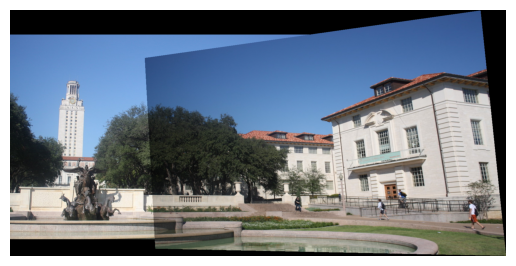

In [14]:
mosaic= create_mosaic(img1, img2, H_mat)
plt.imshow(cv2.cvtColor(mosaic, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

# Three image stitch

In [15]:
img1_path= "assets/shanghai-21.png"
img2_path= "assets/shanghai-22.png"
img3_path= "assets/shanghai-23.png"

In [16]:
img1= cv2.imread(img1_path)
img2= cv2.imread(img2_path)
img3= cv2.imread(img3_path)

In [17]:
cv2.imshow('img1',img1)
cv2.imshow('img2',img2)
cv2.imshow('img3',img3)
cv2.waitKey()
cv2.destroyAllWindows()

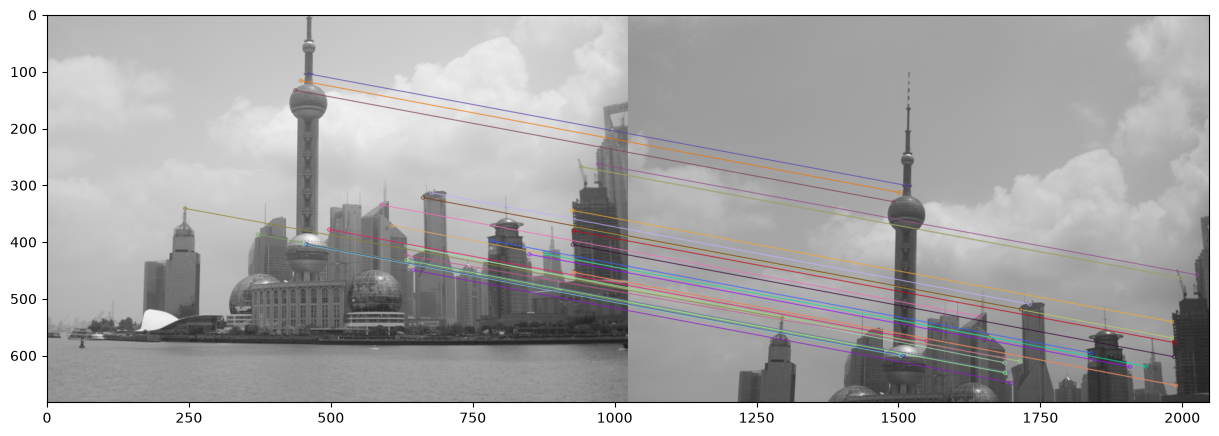

[[ 9.45487870e-01 -5.67205053e-02  5.14342117e+01]
 [-9.92160615e-03  9.12678174e-01  2.06208486e+02]
 [-2.25458945e-05 -9.62243017e-05  1.00000000e+00]]


In [18]:
kp1,kp2,matches, match_img= find_correspondences(img1,img2,30)
plt.figure(figsize=(15, 10))
plt.imshow(match_img), plt.show()

H12= compute_homography(kp1, kp2, [m[0] for m in matches])
print(H12)

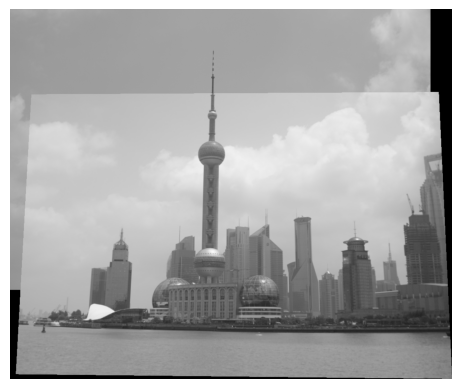

In [19]:
mosaic= create_mosaic(img1, img2, H12)
plt.imshow(cv2.cvtColor(mosaic, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## Stitching first output and third img

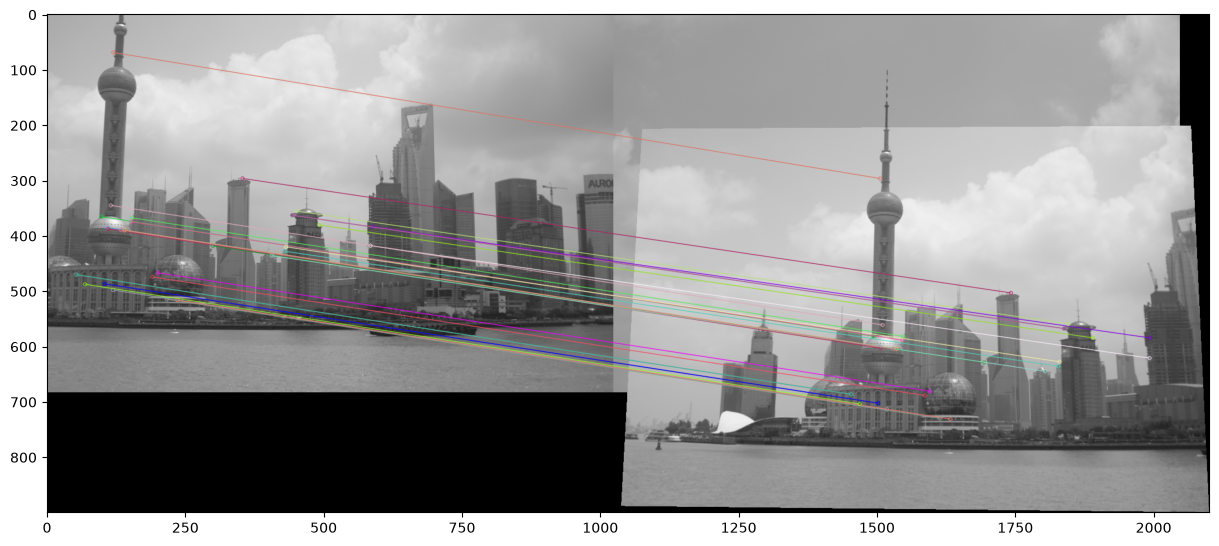

[[ 8.51277289e-01 -2.27697537e-02  3.71992557e+02]
 [-9.90061250e-02  8.81428387e-01  2.41167336e+02]
 [-1.20809524e-04 -9.88109345e-05  1.00000000e+00]]


In [20]:
kp3,kpm,matches, match_img= find_correspondences(img3,mosaic,30)
plt.figure(figsize=(15, 10))
plt.imshow(match_img), plt.show()

H3M= compute_homography(kp3, kpm, [m[0] for m in matches])
print(H3M)

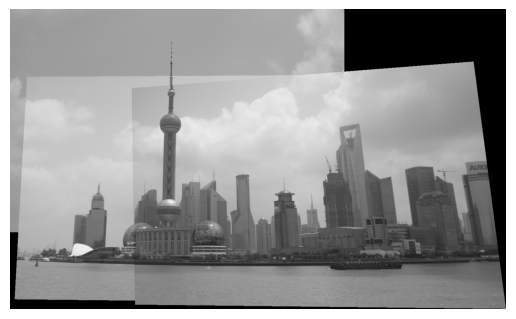

In [21]:
mosaic3= create_mosaic(img3, mosaic, H3M)
plt.imshow(cv2.cvtColor(mosaic3, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()